In [9]:
import sys
sys.path.append('..')
from src.data_loading import load_data, split_train_test_freq
from src.features import preparer, modalites_frequentes, regrouper
from src.graph import plot_freq_par_groupe, freq_par_groupe
import numpy as np
import matplotlib.pyplot as plt



freq, sev = load_data()
train, test = split_train_test_freq(freq, test_size=0.2, random_state=42)

for nom, table in [("train", train), ("test", test)]:
    print(f"Exposition totale de {nom} : ", table["Exposure"].sum().round(3))
    print(f"ClaimNb totale de {nom} : ", table["ClaimNb"].sum())
    print(f"Fréquence annualisée de {nom} : ", (table["ClaimNb"].sum() / table["Exposure"].sum()).round(5))

print("Proportion de l'exposition dans le test : ", (test["ClaimNb"].sum() / (test["ClaimNb"].sum()+train["ClaimNb"].sum())).round(4))

Exposition totale de train :  286776.503
ClaimNb totale de train :  28831
Fréquence annualisée de train :  0.10053
Exposition totale de test :  71583.603
ClaimNb totale de test :  7225
Fréquence annualisée de test :  0.10093
Proportion de l'exposition dans le test :  0.2004


`Exposition` : Même si le split porte sur le nombre de police et non sur l'exposition, le fait que par coïncidence 20% de l'exposition soit sur le jeu de test confirme qu'il n'y a pas de biais entre exposition et probabilité d'être tiré.

`Fréquences` : 0.10053 et 0.10093 cont 0.1005 sur le portefeuille complet. L'écart entre les deux est de 0.4%. Sachant que le test contient 7225 sinistres, l'incertitude relative (mesure suivant une statistique de poisson) sur sa fréquence est de `1/√7224 ≈ 1,2 %`. L'écart observé est environ 3 fois plus petit donc rien à signaler.

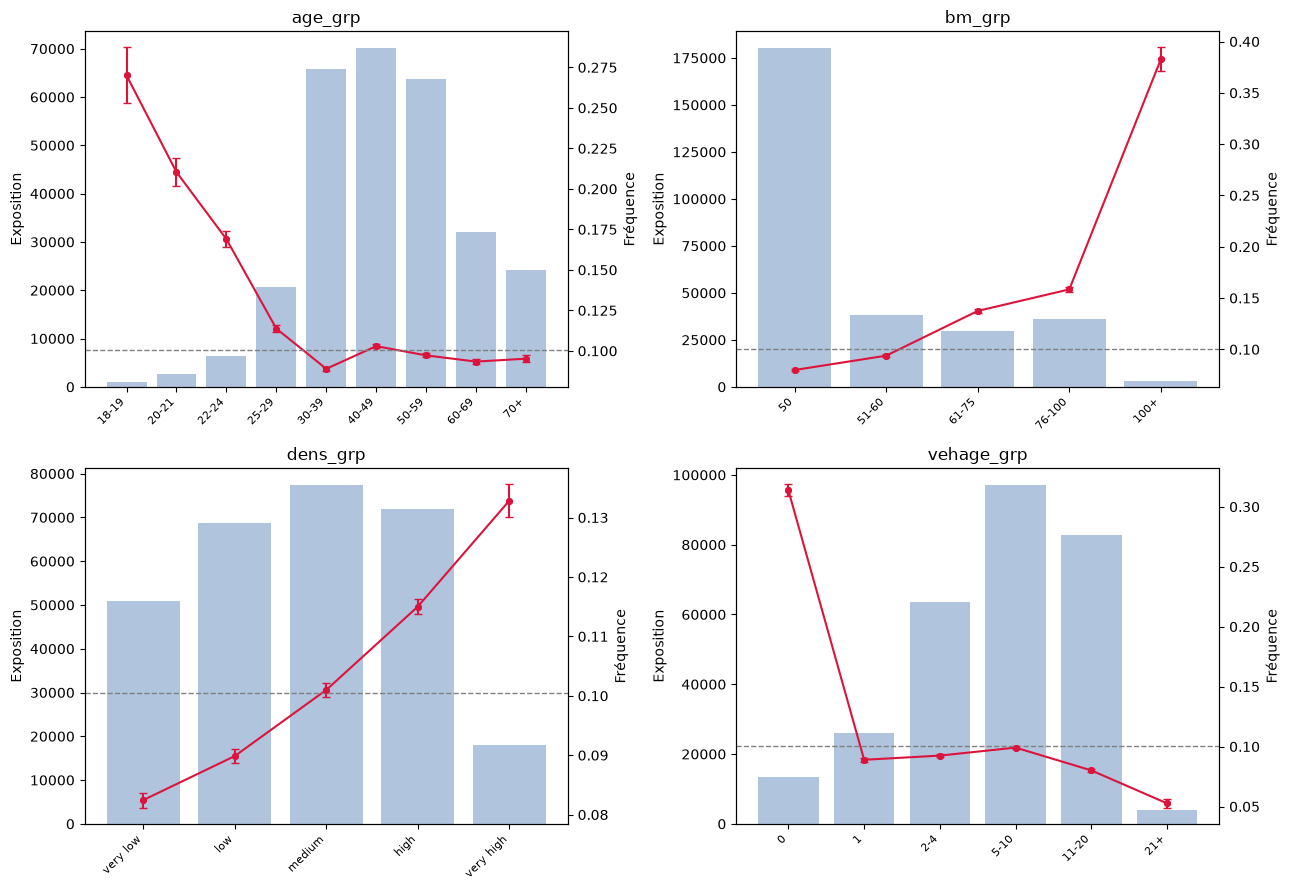

In [10]:
train_prep = preparer(train)
test_prep  = preparer(test)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ["age_grp", "bm_grp", "dens_grp", "vehage_grp"]):
    plot_freq_par_groupe(train_prep, col, ax=ax, errorbar=True)
plt.tight_layout()


In [11]:
modalites = {}
for col in ["Region", "VehBrand", "VehPower"]:
    modalites[col] = modalites_frequentes(train_prep, col)
    train_prep = regrouper(train_prep, col, modalites[col])
    test_prep  = regrouper(test_prep,  col, modalites[col])
print(modalites)


{'Region': ['R11', 'R24', 'R25', 'R31', 'R41', 'R52', 'R53', 'R54', 'R72', 'R73', 'R82', 'R91', 'R93'], 'VehBrand': ['B1', 'B10', 'B11', 'B12', 'B13', 'B2', 'B3', 'B4', 'B5', 'B6'], 'VehPower': [4, 5, 6, 7, 8, 9, 10, 11]}


In [ ]:
for col in ["age_grp", "bm_grp", "dens_grp", "vehage_grp"]:
    t = freq_par_groupe(train_prep, col)
    t["err_rel"] = 1 / np.sqrt(t["sinistres"])
    print(t.round(4), "\n")
    

         exposition  sinistres  frequence  err_rel
age_grp                                           
18-19      907.2954        245     0.2700   0.0639
20-21     2671.6727        562     0.2104   0.0422
22-24     6485.5269       1096     0.1690   0.0302
25-29    20628.9914       2347     0.1138   0.0206
30-39    65902.3593       5862     0.0889   0.0131
40-49    70097.0841       7215     0.1029   0.0118
50-59    63834.2543       6207     0.0972   0.0127
60-69    32087.1606       2997     0.0934   0.0183
70+      24162.1581       2300     0.0952   0.0209 

         exposition  sinistres  frequence  err_rel
bm_grp                                            
50      180133.2203      14391     0.0799   0.0083
51-60    38355.5510       3600     0.0939   0.0167
61-75    29563.1775       4064     0.1375   0.0157
76-100   35867.8964       5683     0.1584   0.0133
100+      2856.6576       1093     0.3826   0.0302 

           exposition  sinistres  frequence  err_rel
dens_grp                 